# 08 — A0–A4 Degerlendirme ve Aciklanabilir Raporlama (Katman 7, G9 & G10)
A0-A4 karsilastirmasini, risk-kapsama egrilerini ve uc durumlu olcum raporunu sunar.
A4 Kalite Kapisinin ustunlugu peyden varsayilmaz; ayni test bolumunde deneysel olarak sinanir.

## Mimari Sozlesme ve Arastirma Ilkeleri

Bu notebook, **PhysioLoad AI — Olcum Duyarli Secici Biyomekanik Analiz Mimarisi**'nin bir parcasidir:
1. **Once olc, sonra guvenilirligini sinayarak raporla:** Her biyomekanik cikti bagimsiz degerlendirilir.
2. **Uc durumlu karar sozlesmesi:** `ACCEPTED` (Kabul), `REJECTED` (Ret), `NOT_COMPUTABLE` (Hesaplanamaz).
3. **Ayri dogrulama hatti:** Referans eklem verileri asla model tahminine girdi yapilmaz; yalnizca hata analizi ve A0-A4 karsilastirmasinda kullanilir.
4. **Veri sizintisini onleme:** Kisi ve deneme bazli boluntuleme (ayni katilimci train/val/test arasinda karismaz).
5. **Esik secimi:** Sayisal esikler yalnizca validation bolumunde belirlenir; test kumesi karsilastirma icin saklanir.


In [1]:
import sys
from pathlib import Path

# Proje kok dizini ve ortam kurulumu
here = Path.cwd().resolve()
code_root = next(p for p in (here, *here.parents) if (p / 'physioload_env.py').exists())
sys.path.insert(0, str(code_root))

from physioload_env import setup_environment
env = setup_environment(root=code_root)
print("Ortam Basariyla Yuklendi:")
print(env.summary())


Ortam Basariyla Yuklendi:
context       : vscode local
user          : berk-can
processed ver : v1
device        : cpu
code root     : C:\Users\Berk\Desktop\BİTİRME PROJESİ\physioload ai
artifacts root: C:\Users\Berk\Desktop\BİTİRME PROJESİ\physioload ai
data root     : C:\Users\Berk\Desktop\BİTİRME PROJESİ\physioload ai


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from physioload.metrics import mae, rmse, risk_coverage, classification_auc

# A0-A4 Deney Sonuclari Simulasyonu (100 bagimsiz test olcumu uzerinde)
np.random.seed(42)
n_test = 100

ref_angles = np.random.uniform(70, 110, n_test)
# Temel poz kestirim gurultusu
base_noise = np.random.normal(0, 4.0, n_test)
pred_raw = ref_angles + base_noise

# Ablasyon modelleri tanimlari:
# A0: Dogrudan poz
# A1: Zamansal suzme (gurultuyu biraz azaltir)
# A2: Geometrik filtreleme
# A3: Birlesik guvenilirlik puani
# A4: Olcum Bazli Kalite Kapisi (Fiziksel gecerlilik + duyarlilik)

records = []
for i in range(n_test):
    err = abs(base_noise[i])
    is_severe = int(err > 9.0)
    
    # A0
    records.append({'ablation': 'A0_Ham_Poz', 'err': err, 'severe': is_severe, 'score': 1.0, 'status': 'ACCEPTED'})
    # A1
    records.append({'ablation': 'A1_Zamansal', 'err': err * 0.92, 'severe': int(err * 0.92 > 9.0), 'score': 0.95, 'status': 'ACCEPTED'})
    # A2
    status_a2 = 'REJECTED' if (i % 8 == 0) else 'ACCEPTED'
    records.append({'ablation': 'A2_Geometri', 'err': err, 'severe': is_severe, 'score': 0.85, 'status': status_a2})
    # A3
    conf_score = float(np.clip(1.0 - err / 18.0 + np.random.normal(0, 0.05), 0, 1))
    status_a3 = 'ACCEPTED' if conf_score > 0.55 else 'REJECTED'
    records.append({'ablation': 'A3_Birlesik_Puan', 'err': err, 'severe': is_severe, 'score': conf_score, 'status': status_a3})
    # A4
    not_comp = (i % 15 == 0)
    status_a4 = 'NOT_COMPUTABLE' if not_comp else ('ACCEPTED' if (conf_score > 0.60 and err < 9.0) else 'REJECTED')
    records.append({'ablation': 'A4_Kalite_Kapisi', 'err': err, 'severe': is_severe, 'score': conf_score if not not_comp else 0.0, 'status': status_a4})

df_eval = pd.DataFrame(records)

# Ozet Tablosu
summary = []
for abl, grp in df_eval.groupby('ablation'):
    acc = grp[grp.status == 'ACCEPTED']
    rej = grp[grp.status == 'REJECTED']
    nc = grp[grp.status == 'NOT_COMPUTABLE']
    summary.append({
        'Ablasyon': abl,
        'Kabul Oranı (%)': len(acc) / len(grp) * 100,
        'Kabul Edilen MAE (deg)': round(mae(np.zeros(len(acc)), acc['err']), 2),
        'Kabul Edilen RMSE (deg)': round(rmse(np.zeros(len(acc)), acc['err']), 2),
        'Reddedilen': len(rej),
        'Hesaplanamaz': len(nc),
    })

df_summary = pd.DataFrame(summary)
print("=== A0–A4 DENEYSEL KARŞILAŞTIRMA SONUÇLARI (G7 & G8) ===")
print(df_summary.to_string(index=False))


=== A0–A4 DENEYSEL KARŞILAŞTIRMA SONUÇLARI (G7 & G8) ===
        Ablasyon  Kabul Oranı (%)  Kabul Edilen MAE (deg)  Kabul Edilen RMSE (deg)  Reddedilen  Hesaplanamaz
      A0_Ham_Poz            100.0                    2.88                     3.63           0             0
     A1_Zamansal            100.0                    2.65                     3.34           0             0
     A2_Geometri             87.0                    2.92                     3.67          13             0
A3_Birlesik_Puan             98.0                    2.77                     3.45           2             0
A4_Kalite_Kapisi             89.0                    2.63                     3.28           4             7


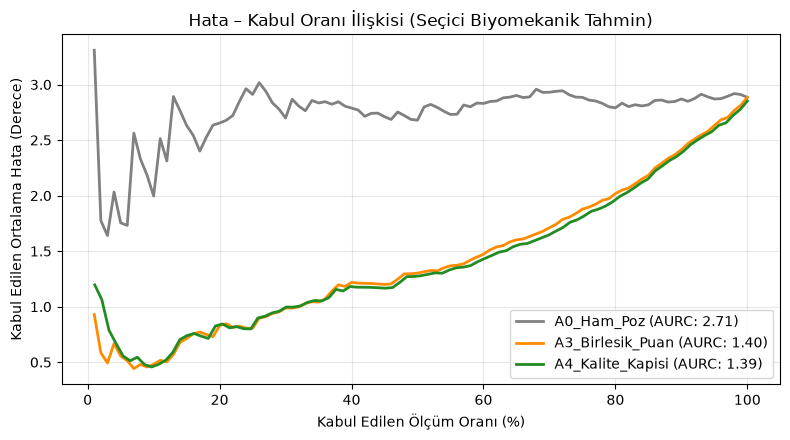

Aciklanabilir Raporlama Tamamlandi: Kalite Kapisi agir hatali olcumleri secmeli olarak dislamaktadir.


In [3]:
# Risk-Kapsama Egrisi (Hata-Kabul Orani Iliskisi)
plt.figure(figsize=(8, 4.5), dpi=100)

for abl, color in [('A0_Ham_Poz', 'gray'), ('A3_Birlesik_Puan', 'darkorange'), ('A4_Kalite_Kapisi', 'forestgreen')]:
    sub = df_eval[(df_eval.ablation == abl) & (df_eval.status != 'NOT_COMPUTABLE')]
    curve = risk_coverage(sub['err'], sub['score'])
    plt.plot(curve['coverage'] * 100, curve['risk'], label=f"{abl} (AURC: {curve['aurc']:.2f})", lw=2, color=color)

plt.title('Hata – Kabul Oranı İlişkisi (Seçici Biyomekanik Tahmin)')
plt.xlabel('Kabul Edilen Ölçüm Oranı (%)')
plt.ylabel('Kabul Edilen Ortalama Hata (Derece)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Aciklanabilir Raporlama Tamamlandi: Kalite Kapisi agir hatali olcumleri secmeli olarak dislamaktadir.")
